# [SNA - Nhóm 09] DEMO MODULE T02: CHẠY 3 EXPLAINERS TRÊN BA-SHAPES & CORA
**Dành cho:** Nguyễn Hải Thiện & Nguyễn Trọng Khôi (Colab / Local)  
**Quy ước tuân thủ:** BG03, BG04, BG05, BG06, BG07, BG10  
**Explainers:**
1. **Saliency** (Gradient-based) - Khôi phụ trách
2. **GNNExplainer** (Mutual Information Mask Optimization) - Khôi phụ trách
3. **PGExplainer** (Parameterized Neural Explainer) - Thiện phụ trách


In [1]:
import sys
import pathlib
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Thêm đường dẫn project
ROOT = pathlib.Path('.').resolve().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from t01_handover.load_t01 import load
from t02_explainers import explain_edges, get_candidate_edges, PGExplainer

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Thiết bị: {device}")


Thiết bị: cuda


In [2]:
# 1. Nạp BA-Shapes
data, model, pred, val_nodes = load('bashapes', root=ROOT / 't01_handover')
model = model.to(device)

print(f"Số node: {data['stats']['nodes']} | Số cạnh: {data['stats']['edge_entries']}")
print(f"Số validation nodes: {len(val_nodes)}")

# Chọn 1 node validation thuộc Class 3 (mái nhà) để giải thích
# Class 3 là lớp trước đây bị lỗi, giờ đã fix chuẩn!
val_c3 = [n for n in val_nodes if data['y'][n] == 3 and pred[n] == 3]
target_node = val_c3[0] if len(val_c3) > 0 else val_nodes[0]
target_class = int(pred[target_node])

print(f"Node giải thích: {target_node} | Nhãn thật: {int(data['y'][target_node])} | Lớp dự đoán: {target_class}")


Số node: 700 | Số cạnh: 3972
Số validation nodes: 100
Node giải thích: 374 | Nhãn thật: 3 | Lớp dự đoán: 3


In [3]:
# 2. Trích xuất tập cạnh ứng viên 2-hop theo BG05
candidate_edges = get_candidate_edges(data['edge_index'], target_node, num_hops=2)
m = candidate_edges['num_candidate_edges']
print(f"Số cạnh ứng viên trong vùng 2-hop: {m}")
print("Danh sách các cặp cạnh (u, v):", candidate_edges['candidate_pairs'])


Số cạnh ứng viên trong vùng 2-hop: 6
Danh sách các cặp cạnh (u, v): [(370, 371), (370, 373), (370, 374), (371, 372), (371, 374), (372, 373)]


In [4]:
# 3. Chạy Saliency (Khôi)
edge_ids, scores_sal, rt_sal, st_sal, _ = explain_edges(
    model=model,
    data=data,
    node_id=target_node,
    target_class=target_class,
    candidate_edges=candidate_edges,
    config={'method': 'saliency'},
    seed=0
)
print(f"[Saliency] Status: {st_sal} | Runtime: {rt_sal:.4f}s")


[Saliency] Status: success | Runtime: 0.4197s


In [5]:
# 4. Chạy GNNExplainer (Khôi)
edge_ids, scores_gnn, rt_gnn, st_gnn, _ = explain_edges(
    model=model,
    data=data,
    node_id=target_node,
    target_class=target_class,
    candidate_edges=candidate_edges,
    config={'method': 'gnnexplainer', 'epochs': 150, 'lr': 0.01},
    seed=0
)
print(f"[GNNExplainer] Status: {st_gnn} | Runtime: {rt_gnn:.4f}s")


[GNNExplainer] Status: success | Runtime: 1.4326s


In [6]:
# 5. Huấn luyện & Chạy PGExplainer (Thiện)
# Huấn luyện chỉ trên train_mask theo đúng BG03
pg_model = PGExplainer(model=model, emb_dim=model.c1.out_channels, device=device)
t_train = pg_model.train_explainer(data=data, epochs=30, lr=0.005, seed=0)
print(f"Huấn luyện PGExplainer hoàn tất trong: {t_train:.2f}s")

edge_ids, scores_pge, rt_pge, st_pge, _ = explain_edges(
    model=model,
    data=data,
    node_id=target_node,
    target_class=target_class,
    candidate_edges=candidate_edges,
    config={'method': 'pgexplainer'},
    seed=0,
    pg_instance=pg_model
)
print(f"[PGExplainer] Status: {st_pge} | Runtime: {rt_pge:.4f}s")


Huấn luyện PGExplainer hoàn tất trong: 0.37s
[PGExplainer] Status: success | Runtime: 0.0060s


In [7]:
# 6. Bảng so sánh điểm quan trọng của các cạnh giữa 3 Explainer
df_scores = pd.DataFrame({
    'edge_id': edge_ids,
    'pair': [str(p) for p in candidate_edges['candidate_pairs']],
    'Saliency': np.round(scores_sal, 4),
    'GNNExplainer': np.round(scores_gnn, 4),
    'PGExplainer': np.round(scores_pge, 4)
})

# Kiểm tra cạnh có thuộc ground truth motif nhà hay không
gt_mask = data.get('gt_edge_mask')
if gt_mask is not None:
    src_all = data['edge_index'][0].cpu().numpy()
    dst_all = data['edge_index'][1].cpu().numpy()
    gt_pairs = set()
    for j, is_gt in enumerate(gt_mask):
        if is_gt:
            gt_pairs.add((int(min(src_all[j], dst_all[j])), int(max(src_all[j], dst_all[j]))))
    df_scores['Is_GT_Motif'] = [p in gt_pairs for p in candidate_edges['candidate_pairs']]

print(df_scores.sort_values(by='GNNExplainer', ascending=False).to_string())


   edge_id        pair  Saliency  GNNExplainer  PGExplainer  Is_GT_Motif
0        0  (370, 371)    0.7847        0.9073          1.0         True
4        4  (371, 374)    1.3170        0.8551          1.0         True
2        2  (370, 374)    3.0185        0.8393          1.0         True
1        1  (370, 373)    0.3439        0.4912          1.0         True
3        3  (371, 372)    0.9230        0.4140          1.0         True
5        5  (372, 373)    0.1859        0.3642          1.0         True


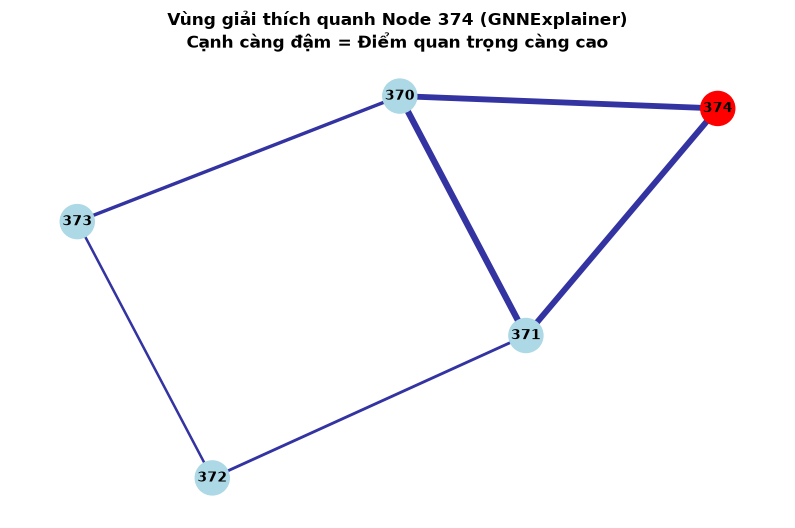

In [8]:
# 7. Trực quan hóa Subgraph giải thích bằng NetworkX
sub_nodes = candidate_edges['subgraph_nodes'].cpu().numpy().tolist()
sub_pairs = candidate_edges['candidate_pairs']

G = nx.Graph()
G.add_nodes_from(sub_nodes)
G.add_edges_from(sub_pairs)

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 6))
node_colors = ['red' if n == target_node else 'lightblue' for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=600)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

weights = [max(0.5, scores_gnn[i] * 5.0) for i in range(len(sub_pairs))]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='darkblue', alpha=0.8)

plt.title(f"Vùng giải thích quanh Node {target_node} (GNNExplainer)\nCạnh càng đậm = Điểm quan trọng càng cao", fontsize=12, fontweight='bold')
plt.axis('off')
plt.show()


In [9]:
# 8. Xuất file kết quả mẫu edge_scores.csv tuân thủ quy ước BG10
records = []
for m_name, s_list in [('saliency', scores_sal), ('gnnexplainer', scores_gnn), ('pgexplainer', scores_pge)]:
    for eid, (u, v), s in zip(edge_ids, candidate_edges['candidate_pairs'], s_list):
        records.append({
            'run_id': f'demo_{m_name}_node{target_node}',
            'method': m_name,
            'node_id': target_node,
            'edge_id': eid,
            'src': u,
            'dst': v,
            'score': float(s)
        })

df_export = pd.DataFrame(records)
export_path = ROOT / 'notebooks' / 'sample_edge_scores.csv'
df_export.to_csv(export_path, index=False, encoding='utf-8')
print(f"Đã xuất file kết quả mẫu tuân thủ BG10 tại: {export_path}")
print(df_export.head(10).to_string())


Đã xuất file kết quả mẫu tuân thủ BG10 tại: D:\WorkSpace\UIT\SocialNetwork\DoAn\notebooks\sample_edge_scores.csv
                      run_id        method  node_id  edge_id  src  dst     score
0      demo_saliency_node374      saliency      374        0  370  371  0.784652
1      demo_saliency_node374      saliency      374        1  370  373  0.343944
2      demo_saliency_node374      saliency      374        2  370  374  3.018454
3      demo_saliency_node374      saliency      374        3  371  372  0.922998
4      demo_saliency_node374      saliency      374        4  371  374  1.316957
5      demo_saliency_node374      saliency      374        5  372  373  0.185914
6  demo_gnnexplainer_node374  gnnexplainer      374        0  370  371  0.907285
7  demo_gnnexplainer_node374  gnnexplainer      374        1  370  373  0.491181
8  demo_gnnexplainer_node374  gnnexplainer      374        2  370  374  0.839259
9  demo_gnnexplainer_node374  gnnexplainer      374        3  371  372  0.413